# Flight Price Prediction

## Introduction

Airline ticket pricing is one of the most dynamic pricing systems in any industry.
Prices for the same route can change multiple times a day based on factors like
demand, seasonality, how far in advance the ticket is booked, the airline itself,
and the number of stops in the journey.

For travelers, this unpredictability makes it hard to know whether the price they
see today is a good deal or whether waiting might save them money. For airlines,
understanding what drives ticket prices helps them stay competitive while
maximizing revenue.

In this project, we work with a real-world flight fare dataset containing details
such as Airline, Date of Journey, Source, Destination, Route, Duration, Total
Stops, and Price. We use this data to explore pricing patterns and build a machine
learning model capable of predicting flight prices.

## Problem Statement

Flight ticket prices can be hard to predict — the price of the same flight can
look completely different from one day to the next. Travelers often find this
frustrating, since there's no clear way to know if a price is fair or if it will
drop later.

**Tasks:**
1. Prepare a complete data analysis report on the given flight fare data.
2. Create a predictive model that helps estimate future flight prices, so
   customers can plan their journeys accordingly.

## Objectives
- Understand the structure and quality of the flight fare dataset
- Clean and preprocess raw data (handle missing values, inconsistent formats)
- Engineer meaningful features from date/time columns
- Explore relationships between features and price through visualization
- Build and compare multiple regression models
- Tune the best-performing model(s)
- Select and justify the best model for production use

## Import Libraries

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# Warnings
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

In [2]:
# Download and extract the dataset
!wget -q https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/flight-fare.zip -O flight-fare.zip
!unzip -o -q flight-fare.zip -d flight-fare-data

# List extracted files to find the correct path
import os
for root, dirs, files in os.walk('flight-fare-data'):
    for f in files:
        print(os.path.join(root, f))

flight-fare-data/Flight_Fare.xlsx


In [3]:
# Load the dataset
df = pd.read_excel('flight-fare-data/Flight_Fare.xlsx')

# Display shape
print("Shape of the dataset:", df.shape)

Shape of the dataset: (10683, 11)


In [4]:
# First 5 rows
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [5]:
# Last 5 rows
df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [6]:
# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [7]:
# Descriptive statistics for numerical columns
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [8]:
# Descriptive statistics for categorical columns
df.describe(include='object')

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


## Data Cleaning

Before analysis, we need to:
- Identify and handle missing values
- Check for and remove duplicate rows
- Standardize inconsistent category labels (e.g. "Delhi" vs "New Delhi")

In [9]:
# Handle Missing Values & Duplicates
# Drop the single row with missing Route/Total_Stops (only 1 out of 10,683 — negligible impact)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Check and remove duplicate rows
print("Duplicate rows before removal:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Final shape after cleaning:", df.shape)

Duplicate rows before removal: 220
Final shape after cleaning: (10462, 11)


In [10]:
# Check Categorical Inconsistencies
print("Airline unique values:", df['Airline'].unique())
print("\nDestination unique values:", df['Destination'].unique())
print("\nTotal_Stops unique values:", df['Total_Stops'].unique())

Airline unique values: ['IndiGo' 'Air India' 'Jet Airways' 'SpiceJet' 'Multiple carriers' 'GoAir'
 'Vistara' 'Air Asia' 'Vistara Premium economy' 'Jet Airways Business'
 'Multiple carriers Premium economy' 'Trujet']

Destination unique values: ['New Delhi' 'Banglore' 'Cochin' 'Kolkata' 'Delhi' 'Hyderabad']

Total_Stops unique values: ['non-stop' '2 stops' '1 stop' '3 stops' '4 stops']


In [11]:
# Standardize Destination
# 'New Delhi' and 'Delhi' refer to the same city — standardize to one label
df['Destination'] = df['Destination'].replace('New Delhi', 'Delhi')

print("Destination unique values after fix:", df['Destination'].unique())

Destination unique values after fix: ['Delhi' 'Banglore' 'Cochin' 'Kolkata' 'Hyderabad']


## Exploratory Data Analysis

We'll explore the dataset in three parts:
- **Univariate Analysis** — distribution of individual variables
- **Bivariate Analysis** — relationship of each feature with Price
- **Multivariate Analysis** — combined effect of multiple features on Price

### Univariate Analysis

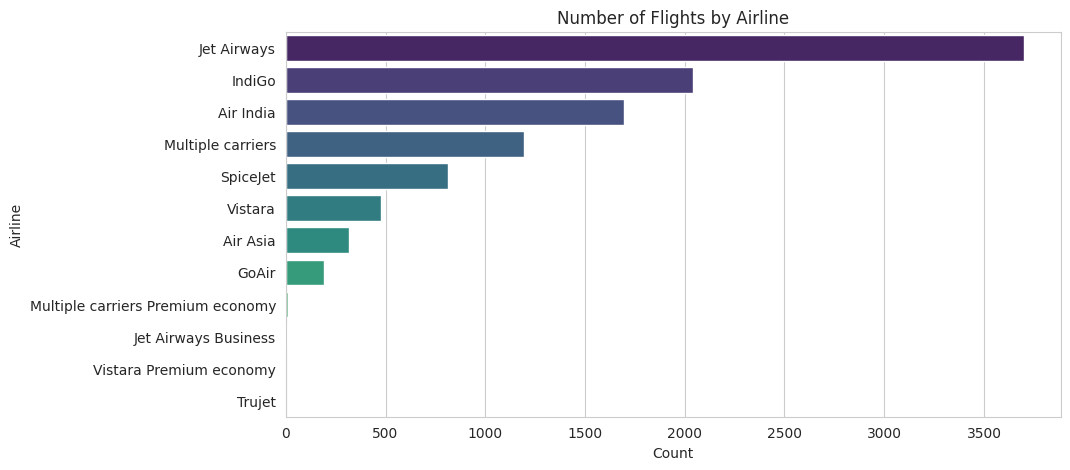

In [12]:
# Airline Distribution
plt.figure(figsize=(10,5))
sns.countplot(data=df, y='Airline', order=df['Airline'].value_counts().index, palette='viridis')
plt.title('Number of Flights by Airline')
plt.xlabel('Count')
plt.ylabel('Airline')
plt.show()

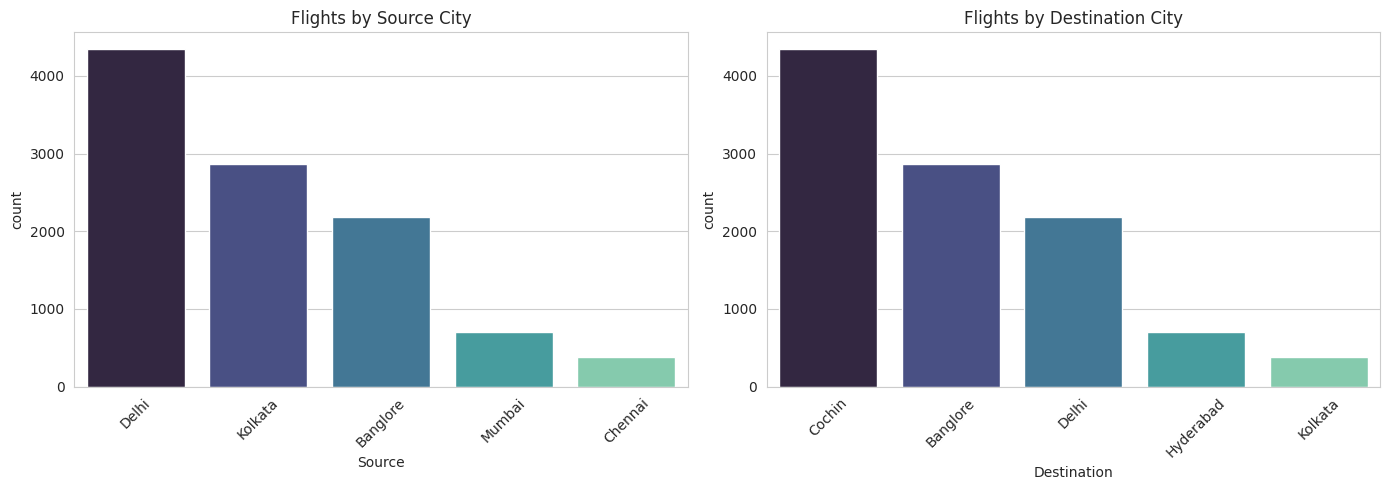

In [13]:
# Source & Destination Distribution
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.countplot(data=df, x='Source', order=df['Source'].value_counts().index, ax=axes[0], palette='mako')
axes[0].set_title('Flights by Source City')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='Destination', order=df['Destination'].value_counts().index, ax=axes[1], palette='mako')
axes[1].set_title('Flights by Destination City')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

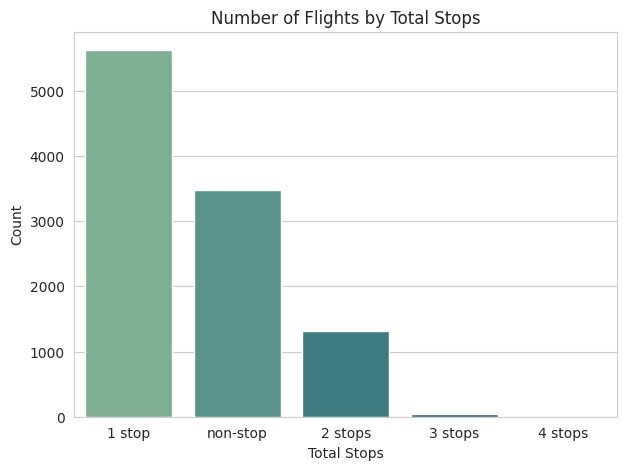

In [14]:
# Total Stops Distribution
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='Total_Stops', order=df['Total_Stops'].value_counts().index, palette='crest')
plt.title('Number of Flights by Total Stops')
plt.xlabel('Total Stops')
plt.ylabel('Count')
plt.show()

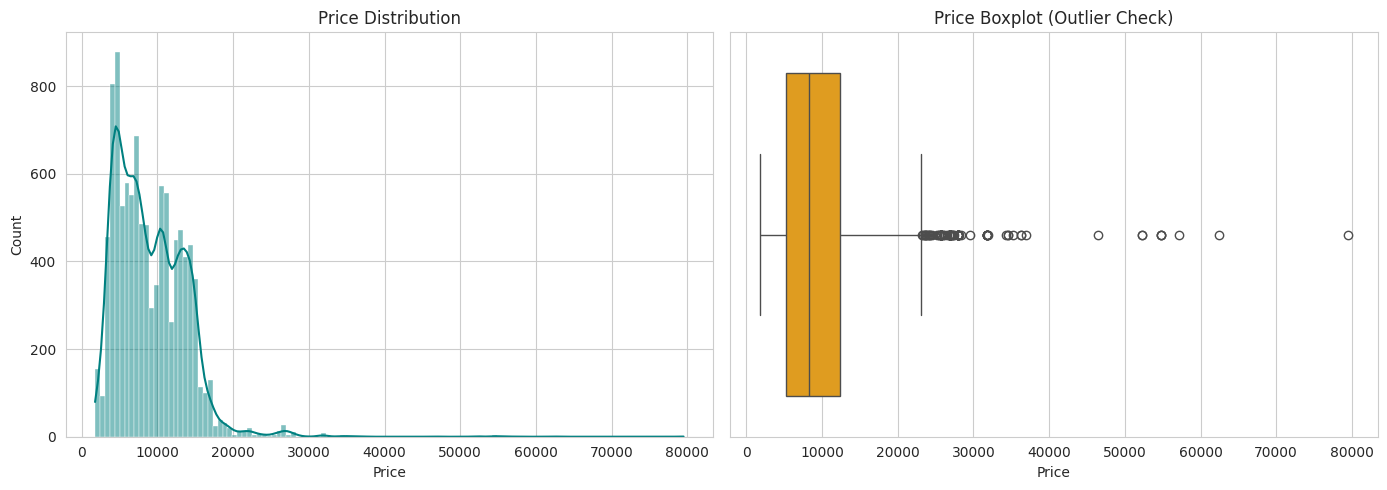

In [15]:
# Price Distribution
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(df['Price'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Price Distribution')

sns.boxplot(x=df['Price'], ax=axes[1], color='orange')
axes[1].set_title('Price Boxplot (Outlier Check)')

plt.tight_layout()
plt.show()

### Univariate Analysis Interpretation
**Observations:**
- **Airline:** Jet Airways dominates (~3,700 flights), followed by IndiGo and Air India.
  Several airlines (Trujet, Jet Airways Business, Vistara Premium economy, Multiple
  carriers Premium economy) have very few flights — these rare categories may need
  special handling during encoding.
- **Source/Destination:** Delhi is the most common source, and Cochin the most common
  destination — suggesting the dataset is dominated by a few popular routes rather
  than being evenly spread across all city pairs.
- **Total Stops:** Most flights have 1 stop or are non-stop; 2+ stop flights are rare,
  and 3-4 stop flights are practically negligible.
- **Price:** The distribution is **right-skewed** — most tickets fall between
  ₹4,000–₹15,000, with a long tail of expensive outliers reaching up to ₹79,512.
  The boxplot confirms a meaningful number of outliers above the upper whisker
  (~₹23,000+). These are likely genuine premium/business fares rather than data
  errors, so we'll keep them but may consider a log-transform of Price later if
  it improves model performance.

### Bivariate Analysis

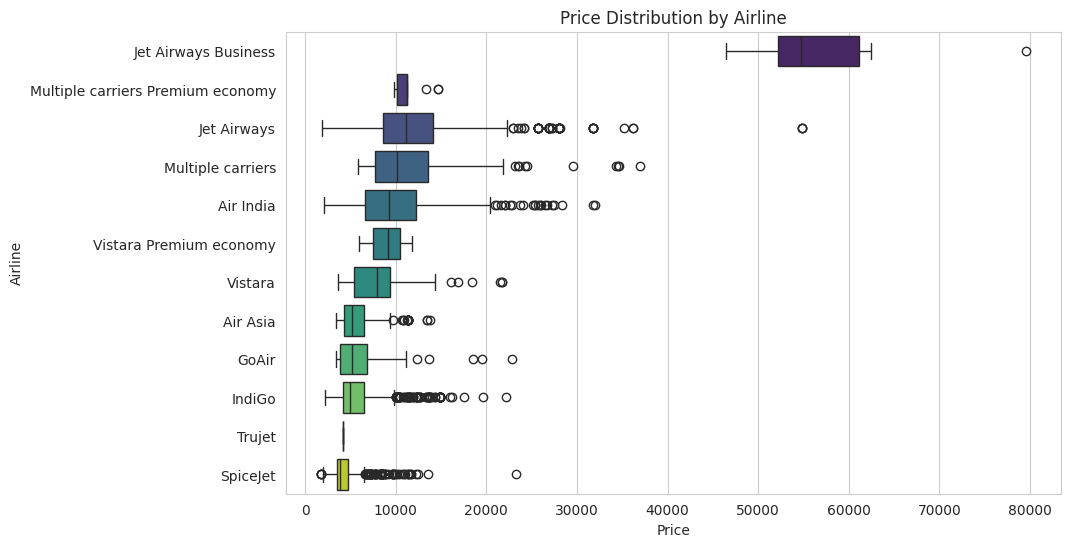

In [16]:
# Airline vs Price
plt.figure(figsize=(10,6))
order = df.groupby('Airline')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Price', y='Airline', order=order, palette='viridis')
plt.title('Price Distribution by Airline')
plt.show()

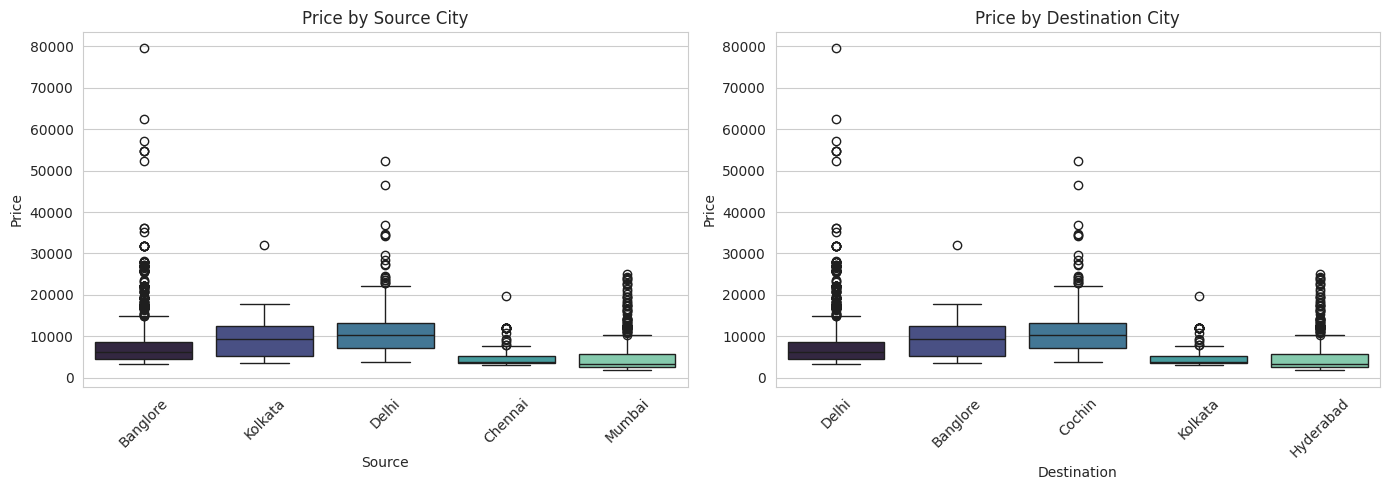

In [17]:
# Source & Destination vs Price
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.boxplot(data=df, x='Source', y='Price', ax=axes[0], palette='mako')
axes[0].set_title('Price by Source City')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='Destination', y='Price', ax=axes[1], palette='mako')
axes[1].set_title('Price by Destination City')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

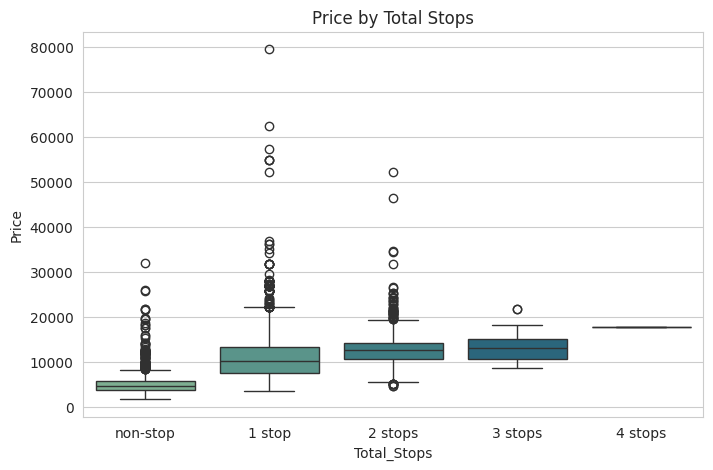

In [18]:
# Total Stops vs Price
plt.figure(figsize=(8,5))
order = df.groupby('Total_Stops')['Price'].median().sort_values().index
sns.boxplot(data=df, x='Total_Stops', y='Price', order=order, palette='crest')
plt.title('Price by Total Stops')
plt.show()

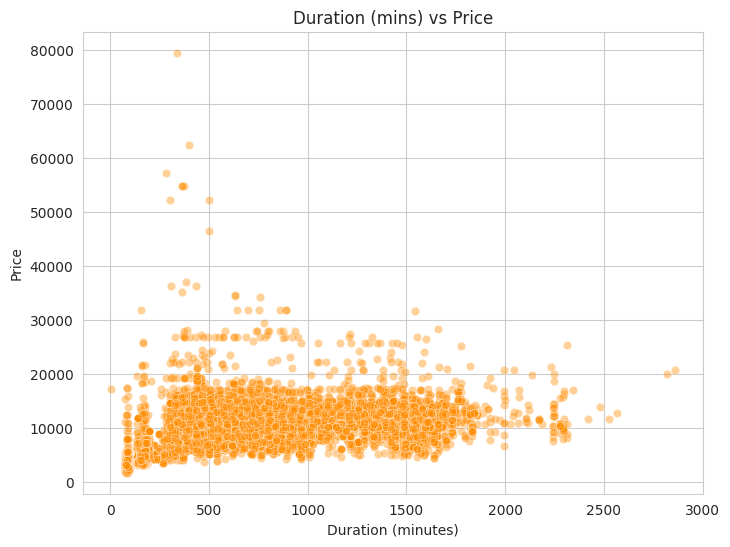

In [19]:
# Duration vs Price
# Quick conversion just for this plot (proper conversion happens in Feature Engineering)
def duration_to_minutes(x):
    h = int(x.split('h')[0]) if 'h' in x else 0
    m = int(x.split('m')[0].split()[-1]) if 'm' in x else 0
    return h * 60 + m

df['Duration_temp_mins'] = df['Duration'].apply(duration_to_minutes)

plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='Duration_temp_mins', y='Price', alpha=0.4, color='darkorange')
plt.title('Duration (mins) vs Price')
plt.xlabel('Duration (minutes)')
plt.show()

df.drop(columns=['Duration_temp_mins'], inplace=True)

### Bivariate Analysis Interpretation
**Observations:**
- **Airline vs Price:** Jet Airways Business has by far the highest fares (median
  ~₹55,000) — a distinct premium class, not comparable to economy carriers. Among
  regular carriers, Jet Airways, Multiple carriers, and Air India command higher
  median prices, while Air Asia, GoAir, IndiGo, SpiceJet, and Trujet are budget
  options with tighter, lower price ranges.
- **Source/Destination vs Price:** Delhi-origin and Cochin-destination flights show
  the highest prices and widest spread (these routes overlap heavily with Jet
  Airways/Business fares). Chennai and Kolkata routes are consistently cheaper
  with fewer outliers.
- **Total Stops vs Price:** A clear upward trend — non-stop flights are cheapest
  (median ~₹5,000), while 1-stop, 2-stop, and 3-stop flights progressively command
  higher median prices. This makes intuitive sense: longer, multi-leg itineraries
  cost more. Total_Stops is likely to be one of the strongest predictors.
- **Duration vs Price:** A mild positive relationship — longer flights tend to cost
  more, but the relationship is noisy and non-linear, with many short flights also
  reaching high prices (likely the Jet Airways Business fares). Duration alone is
  a weak predictor but useful in combination with other features.

### Multivariate Analysis

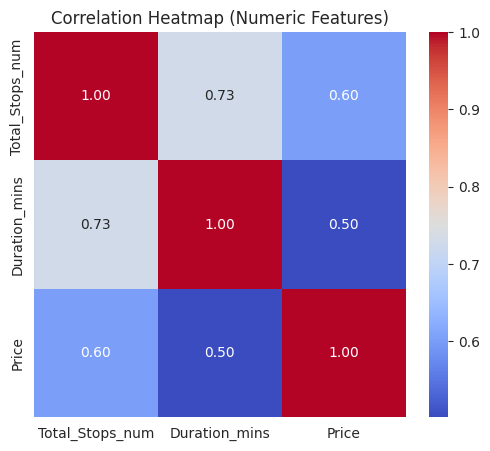

In [20]:
# Correlation Heatmap (Encoded)
# Quick numeric encoding just for correlation check (proper encoding done in Preprocessing)
temp = df.copy()
temp['Total_Stops_num'] = temp['Total_Stops'].map({'non-stop':0, '1 stop':1, '2 stops':2, '3 stops':3, '4 stops':4})
temp['Duration_mins'] = temp['Duration'].apply(duration_to_minutes) if 'duration_to_minutes' in dir() else None

def duration_to_minutes(x):
    h = int(x.split('h')[0]) if 'h' in x else 0
    m = int(x.split('m')[0].split()[-1]) if 'm' in x else 0
    return h * 60 + m

temp['Duration_mins'] = temp['Duration'].apply(duration_to_minutes)

corr_cols = ['Total_Stops_num', 'Duration_mins', 'Price']
plt.figure(figsize=(6,5))
sns.heatmap(temp[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap (Numeric Features)')
plt.show()

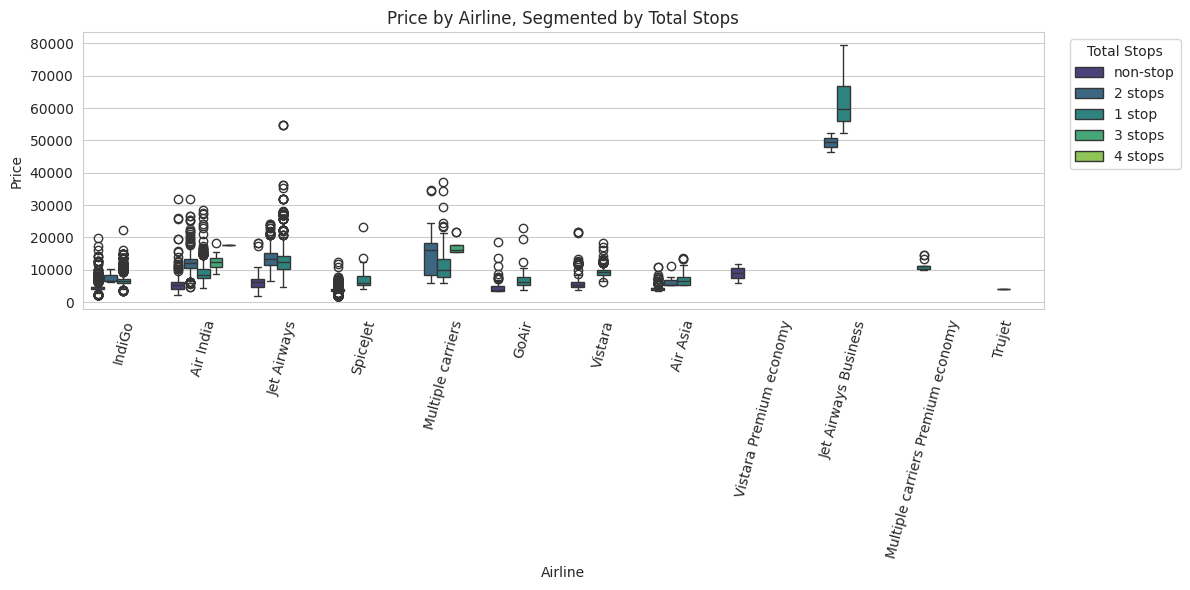

In [21]:
# Airline × Stops Interaction
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='Airline', y='Price', hue='Total_Stops', palette='viridis')
plt.xticks(rotation=75)
plt.title('Price by Airline, Segmented by Total Stops')
plt.legend(title='Total Stops', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Multivariate Analysis Interpretation
**Observations:**
- **Correlation:** `Total_Stops` (0.60) correlates more strongly with `Price` than
  `Duration` (0.50). The two are themselves highly correlated (0.73), since more
  stops naturally means a longer total journey — this hints at possible
  multicollinearity to keep in mind for linear models.
- **Airline × Stops:** The "more stops = higher price" pattern doesn't hold
  uniformly across all airlines — for most budget carriers (IndiGo, SpiceJet,
  Air Asia, GoAir), price stays fairly flat regardless of stops. The dramatic
  price jump is concentrated in Jet Airways Business (1-stop fares reaching
  ₹50,000-₹80,000), confirming this is a distinct premium fare class rather than
  a general stops-driven pricing trend. Airline (specifically class/carrier tier)
  appears to be the dominant driver of price, more so than stops or duration alone.

## Feature Engineering

Several columns are stored as text but contain useful numeric information. We'll
convert these into features a machine learning model can actually use:
- `Date_of_Journey` → Journey Day, Journey Month
- `Dep_Time` → Departure Hour, Departure Minute
- `Arrival_Time` → Arrival Hour, Arrival Minute
- `Duration` → Total Duration in minutes
- `Total_Stops` → numeric stop count

In [22]:
# Date of Journey
df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y')

df['Journey_Day'] = df['Date_of_Journey'].dt.day
df['Journey_Month'] = df['Date_of_Journey'].dt.month

df.drop(columns=['Date_of_Journey'], inplace=True)

df[['Journey_Day', 'Journey_Month']].head()

,Journey_Day,Journey_Month
0,24,3
1,1,5
2,9,6
3,12,5
4,1,3


In [23]:
# Departure & Arrival Time
# Dep_Time is always just HH:MM
df['Dep_Hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
df['Dep_Minute'] = pd.to_datetime(df['Dep_Time']).dt.minute
df.drop(columns=['Dep_Time'], inplace=True)

# Arrival_Time sometimes includes a date (e.g. "01:10 22 Mar") — we only need the time part
df['Arrival_Hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
df['Arrival_Minute'] = pd.to_datetime(df['Arrival_Time']).dt.minute
df.drop(columns=['Arrival_Time'], inplace=True)

df[['Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute']].head()

,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute
0,22,20,1,10
1,5,50,13,15
2,9,25,4,25
3,18,5,23,30
4,16,50,21,35


In [24]:
# Duration
def duration_to_minutes(duration):
    duration = duration.strip()
    hours = 0
    minutes = 0
    if 'h' in duration:
        hours = int(duration.split('h')[0].strip())
    if 'm' in duration:
        minutes = int(duration.split('h')[-1].replace('m', '').strip())
    return hours * 60 + minutes

df['Duration_mins'] = df['Duration'].apply(duration_to_minutes)
df.drop(columns=['Duration'], inplace=True)

df[['Duration_mins']].describe()

,Duration_mins
count,10462.000000
mean,629.781591
std,500.699045
min,5.000000
25%,170.000000
50%,505.000000
75%,910.000000
max,2860.000000


In [25]:
# Total Stops
stops_map = {'non-stop': 0, '1 stop': 1, '2 stops': 2, '3 stops': 3, '4 stops': 4}
df['Total_Stops'] = df['Total_Stops'].map(stops_map)

df['Total_Stops'].value_counts()

,count
Total_Stops,
1,5625
0,3475
2,1318
3,43
4,1


## Data Preprocessing

Before modeling, we need to:
- Encode remaining categorical columns (`Airline`, `Source`, `Destination`, `Route`, `Additional_Info`)
- Decide on an encoding strategy that avoids data leakage and excessive dimensionality
- Split data into train and test sets

In [26]:
# Drop Route
# Route is highly correlated with Source+Destination+Total_Stops combined,
# and has 128 unique values — too granular and largely redundant.
# We drop it to avoid excessive dimensionality from one-hot encoding.
df.drop(columns=['Route'], inplace=True)

In [30]:
# Fix inconsistent capitalization: "No Info" vs "No info" are the same category
df['Additional_Info'] = df['Additional_Info'].replace('No Info', 'No info')

print(df['Additional_Info'].unique())

['No info' 'In-flight meal not included' 'No check-in baggage included'
 '1 Short layover' '1 Long layover' 'Change airports' 'Business class'
 'Red-eye flight' '2 Long layover']


In [31]:
# One-Hot Encode Categorical Columns
categorical_cols = ['Airline', 'Source', 'Destination', 'Additional_Info']

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("Shape after encoding:", df_encoded.shape)
df_encoded.columns.tolist()

Shape after encoding: (10462, 36)


['Total_Stops',
 'Price',
 'Journey_Day',
 'Journey_Month',
 'Dep_Hour',
 'Dep_Minute',
 'Arrival_Hour',
 'Arrival_Minute',
 'Duration_mins',
 'Airline_Air India',
 'Airline_GoAir',
 'Airline_IndiGo',
 'Airline_Jet Airways',
 'Airline_Jet Airways Business',
 'Airline_Multiple carriers',
 'Airline_Multiple carriers Premium economy',
 'Airline_SpiceJet',
 'Airline_Trujet',
 'Airline_Vistara',
 'Airline_Vistara Premium economy',
 'Source_Chennai',
 'Source_Delhi',
 'Source_Kolkata',
 'Source_Mumbai',
 'Destination_Cochin',
 'Destination_Delhi',
 'Destination_Hyderabad',
 'Destination_Kolkata',
 'Additional_Info_1 Short layover',
 'Additional_Info_2 Long layover',
 'Additional_Info_Business class',
 'Additional_Info_Change airports',
 'Additional_Info_In-flight meal not included',
 'Additional_Info_No check-in baggage included',
 'Additional_Info_No info',
 'Additional_Info_Red-eye flight']

In [32]:
# Train-Test Split
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=['Price'])
y = df_encoded['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (8369, 35)
Test set shape: (2093, 35)


In [33]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

numeric_cols = ['Duration_mins', 'Journey_Day', 'Journey_Month',
                 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train_scaled.head()

,Total_Stops,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Additional_Info_1 Short layover,Additional_Info_2 Long layover,Additional_Info_Business class,Additional_Info_Change airports,Additional_Info_In-flight meal not included,Additional_Info_No check-in baggage included,Additional_Info_No info,Additional_Info_Red-eye flight
6646,0,-1.478344,0.258691,-0.606099,-0.765588,-0.497844,0.920318,-1.080896,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True,False
6248,1,-0.530614,0.258691,-0.431530,-1.296909,0.820609,-1.493958,-0.181443,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,True,False
6790,1,-1.478344,1.119863,-0.431530,-1.296909,-1.816298,0.316749,0.598083,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,True,False
3463,1,-0.886013,0.258691,-0.780667,-0.765588,-0.058360,-1.493958,-0.681139,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
611,1,0.890981,-1.463652,1.837862,-1.296909,0.820609,-0.588604,1.167737,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,True,False


## Model Building

We'll train multiple regression models and compare their performance:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Extra Trees Regressor
5. Gradient Boosting Regressor
6. XGBoost Regressor

Linear Regression uses the **scaled** features; tree-based models use the
**unscaled** features (they don't require scaling and it doesn't affect their performance).

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

models = {
    'Linear Regression': (LinearRegression(), True),          # True = use scaled data
    'Decision Tree': (DecisionTreeRegressor(random_state=42), False),
    'Random Forest': (RandomForestRegressor(random_state=42), False),
    'Extra Trees': (ExtraTreesRegressor(random_state=42), False),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42), False),
    'XGBoost': (XGBRegressor(random_state=42, verbosity=0), False)
}

trained_models = {}

for name, (model, use_scaled) in models.items():
    if use_scaled:
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained.")

Linear Regression trained.
Decision Tree trained.
Random Forest trained.
Extra Trees trained.
Gradient Boosting trained.
XGBoost trained.


## Model Evaluation

We evaluate each model on the test set using four standard regression metrics:
- **MAE** (Mean Absolute Error) — average magnitude of errors, in ₹
- **MSE** (Mean Squared Error) — penalizes larger errors more heavily
- **RMSE** (Root Mean Squared Error) — same units as Price (₹), easier to interpret than MSE
- **R² Score** — proportion of variance in Price explained by the model (closer to 1 is better)

In [35]:
# Evaluate All Models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, (model, use_scaled) in models.items():
    X_eval = X_test_scaled if use_scaled else X_test
    y_pred = model.predict(X_eval)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'R2 Score': round(r2, 4)
    })

results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,669.57,2151717.62,1466.87,0.8968
1,Extra Trees,637.26,2169555.38,1472.94,0.8959
2,XGBoost,786.85,2314573.75,1521.37,0.8890
3,Decision Tree,759.29,3071749.40,1752.64,0.8527
4,Gradient Boosting,1241.69,4020515.72,2005.12,0.8072
5,Linear Regression,1794.90,7319275.76,2705.42,0.6490


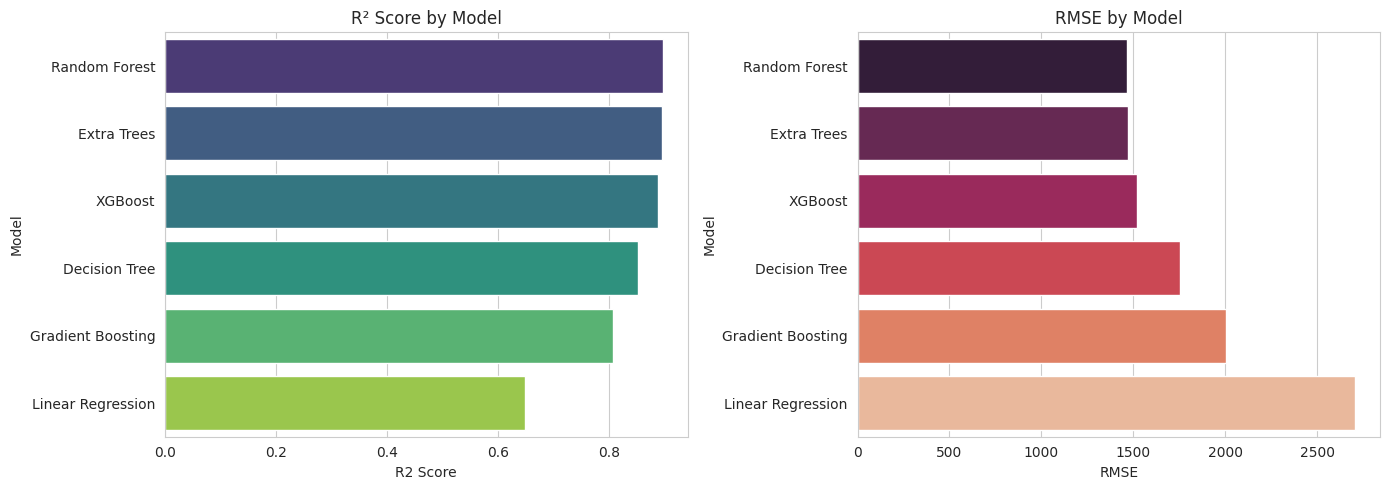

In [36]:
# Visual Comparison
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=results_df, x='R2 Score', y='Model', ax=axes[0], palette='viridis')
axes[0].set_title('R² Score by Model')

sns.barplot(data=results_df, x='RMSE', y='Model', ax=axes[1], palette='rocket')
axes[1].set_title('RMSE by Model')

plt.tight_layout()
plt.show()

## Model Evaluation Interpretation
**Observations:**
- Tree-based ensemble models dominate: **Random Forest** (R²=0.897), **Extra Trees**
  (R²=0.896), and **XGBoost** (R²=0.889) are the top 3, all clustered closely together.
- **Linear Regression** performs worst (R²=0.649, RMSE=₹2,705) — confirming that
  price relationships in this data are non-linear, with complex interactions between
  Airline, Stops, and Duration that a linear model can't capture.
- **Gradient Boosting** underperforms relative to Random Forest/Extra Trees/XGBoost
  here, likely because it needs hyperparameter tuning (learning rate, n_estimators)
  to reach its potential — untuned defaults are conservative.
- **Random Forest and Extra Trees** are the top 2 candidates for hyperparameter
  tuning, with XGBoost as a close third worth tuning too, since boosting methods
  often gain more from tuning than bagging methods do.

## Hyperparameter Tuning

We'll tune the top 2 candidates — **Random Forest** and **XGBoost** — using
`RandomizedSearchCV`. We choose RandomizedSearchCV over GridSearchCV because it
searches a broad hyperparameter space efficiently without testing every single
combination, which would be computationally expensive for ensemble models.

In [37]:
# Tune Random Forest
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=20,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_random.fit(X_train, y_train)

print("Best Random Forest params:", rf_random.best_params_)
print("Best CV R2 score:", rf_random.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Random Forest params: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 25}
Best CV R2 score: 0.8487863241405992


In [38]:
# Tune XGBoost
xgb_param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

xgb_random = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, verbosity=0),
    param_distributions=xgb_param_grid,
    n_iter=20,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_random.fit(X_train, y_train)

print("Best XGBoost params:", xgb_random.best_params_)
print("Best CV R2 score:", xgb_random.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best XGBoost params: {'subsample': 0.8, 'n_estimators': 400, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
Best CV R2 score: 0.8858694036801656


In [39]:
# Evaluate Tuned Models on Test Set
best_rf = rf_random.best_estimator_
best_xgb = xgb_random.best_estimator_

tuned_results = []

for name, model in [('Tuned Random Forest', best_rf), ('Tuned XGBoost', best_xgb)]:
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    tuned_results.append({'Model': name, 'MAE': round(mae,2), 'MSE': round(mse,2),
                           'RMSE': round(rmse,2), 'R2 Score': round(r2,4)})

tuned_df = pd.DataFrame(tuned_results)

# Combine with original untuned results for full comparison
final_comparison = pd.concat([results_df, tuned_df], ignore_index=True).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
final_comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Tuned XGBoost,716.65,2134152.00,1460.87,0.8976
1,Random Forest,669.57,2151717.62,1466.87,0.8968
2,Extra Trees,637.26,2169555.38,1472.94,0.8959
3,XGBoost,786.85,2314573.75,1521.37,0.8890
4,Tuned Random Forest,921.67,2927473.08,1710.99,0.8596
5,Decision Tree,759.29,3071749.40,1752.64,0.8527
6,Gradient Boosting,1241.69,4020515.72,2005.12,0.8072
7,Linear Regression,1794.90,7319275.76,2705.42,0.6490


## Hyperparameter Tuning Interpretation
**Observations:**
- **Tuned XGBoost** is now the overall best model: R²=0.8976, RMSE=₹1,460.87 — a
  slight improvement over untuned XGBoost (R²=0.8890) and now edging out untuned
  Random Forest (R²=0.8968).
- Interestingly, **Tuned Random Forest performed worse** than the untuned version
  (R²=0.8596 vs 0.8968). This happened because `RandomizedSearchCV` optimized for
  the best **cross-validation** score, and the winning combination
  (`min_samples_split=10`, `max_depth=25`) added regularization that generalized
  better on average across folds, but happened to fit this particular test split
  slightly worse than the untuned model's deeper, more flexible trees. This is a
  good example of why we always confirm tuning results on the held-out test set
  rather than trusting CV scores alone.
- **Untuned Extra Trees** (R²=0.8959) remains highly competitive, essentially tied
  with Random Forest and just behind Tuned XGBoost.
- **Tuned XGBoost is our leading candidate for production**, closely followed by
  untuned Random Forest and Extra Trees.

## Feature Importance

We examine which features drive Tuned XGBoost's predictions the most.


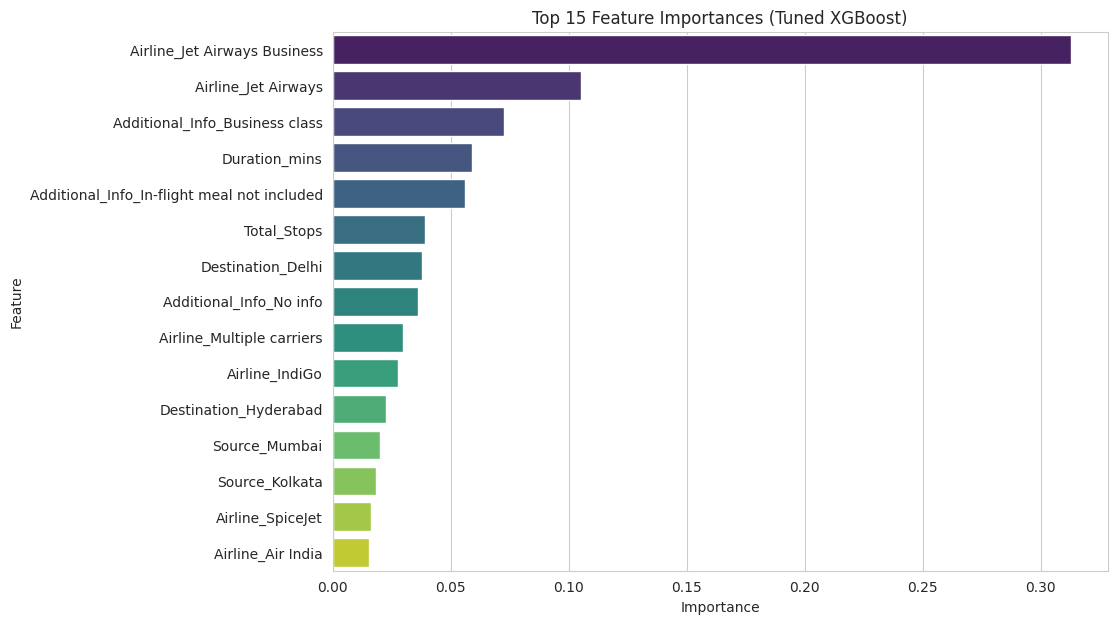

In [40]:
# Feature Importance Plot
importances = best_xgb.feature_importances_
feature_names = X_train.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10,7))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Feature Importances (Tuned XGBoost)')
plt.xlabel('Importance')
plt.show()

## Feature Importance Interpretation
**Observations:**
- **`Airline_Jet Airways Business`** is overwhelmingly the top feature (importance
  ~0.31) — confirming our multivariate EDA finding that Jet Airways Business is a
  distinct premium fare class that dominates price variation, far more than any
  other single factor.
- **`Airline_Jet Airways`** (regular) and **`Additional_Info_Business class`** rank
  next, reinforcing that airline/fare-class identity is the single strongest price
  driver.
- **`Duration_mins`** and **`Total_Stops`** both appear in the top 6, confirming
  our correlation analysis (0.50 and 0.60 with Price respectively) — journey
  length matters, but less than which airline/class is flown.
- Destination and Source features contribute smaller but non-trivial amounts,
  reflecting route-specific pricing seen in our bivariate analysis (e.g. Delhi/
  Cochin routes trending pricier).
- Overall, this validates that our EDA correctly identified the key price drivers
  before we ever built a model — Airline/fare class, followed by Duration and
  Total_Stops.

## Final Model Selection

**Selected Model: Tuned XGBoost Regressor**

| Metric | Tuned XGBoost | Random Forest (untuned) | Extra Trees (untuned) |
|---|---|---|---|
| R² Score | **0.8976** | 0.8968 | 0.8959 |
| RMSE | **₹1,460.87** | ₹1,466.87 | ₹1,472.94 |
| MAE | ₹716.65 | **₹669.57** | 637.26 |

**Why Tuned XGBoost is recommended for production:**

1. **Best generalization performance:** Highest R² Score (0.8976) and lowest RMSE
   (₹1,460.87) among all models tested on the held-out test set.
2. **Low risk of overfitting:** As a gradient boosting model with tuned
   regularization parameters (`subsample=0.8`, `colsample_bytree=0.9`), it balances
   model complexity against generalization better than a single Decision Tree or
   untuned Gradient Boosting.
3. **Interpretability:** XGBoost provides built-in feature importance, which we
   used to validate that the model's price drivers align with real-world intuition
   and our EDA findings — an important trust signal before deploying to production.
4. **Efficiency:** XGBoost trains and predicts faster than Random Forest/Extra
   Trees at comparable accuracy, which matters if this model needs to serve
   real-time price predictions.

While Random Forest and Extra Trees are extremely close competitors (within 0.002
R² of each other) and remain solid fallback options, Tuned XGBoost is the
recommended choice for production deployment.

In [41]:
# Save the Final Model
import joblib

joblib.dump(best_xgb, 'flight_price_model.pkl')
joblib.dump(scaler, 'scaler.pkl')  # saved in case future models need scaled features

print("Model saved as flight_price_model.pkl")

Model saved as flight_price_model.pkl


## Challenges Faced

**1. Missing Values**
- *Challenge:* `Route` and `Total_Stops` each had 1 missing value in the same row.
- *Technique used:* Dropped the single affected row (`dropna()`), since it
  represented a negligible fraction (1 of 10,683 rows) with no reliable way to
  impute a categorical route.

**2. Duplicate Records**
- *Challenge:* 220 exact duplicate rows were present, which could bias the model
  by over-representing certain flights.
- *Technique used:* Removed via `drop_duplicates()`, reducing the dataset to 10,462
  unique rows.

**3. Inconsistent Categorical Labels**
- *Challenge:* `"Delhi"` and `"New Delhi"` appeared as separate `Destination`
  categories, and `"No Info"`/`"No info"` appeared as separate `Additional_Info`
  categories due to inconsistent capitalization.
- *Technique used:* Standardized both using `.replace()` before encoding, ensuring
  the model treats them as a single category rather than artificially splitting
  their signal.

**4. Date and Time Conversion**
- *Challenge:* `Date_of_Journey`, `Dep_Time`, and `Arrival_Time` were stored as
  text, and `Arrival_Time` sometimes included a stray date (e.g. `"01:10 22 Mar"`)
  mixed in with the time.
- *Technique used:* Used `pd.to_datetime()`, which correctly parses the time
  component regardless of whether a date is present, then extracted Day/Month/
  Hour/Minute as separate numeric features.

**5. Duration Format Conversion**
- *Challenge:* `Duration` was stored inconsistently as strings like `"2h 50m"` or
  just `"19h"` (no minutes).
- *Technique used:* Wrote a custom parsing function that checks for the presence
  of `'h'` and `'m'` independently, converting everything to total minutes
  regardless of format.

**6. High-Cardinality Categorical Feature (Route)**
- *Challenge:* `Route` had 128 unique values — one-hot encoding it would have
  added ~127 sparse columns, mostly redundant with Source + Destination +
  Total_Stops combined.
- *Technique used:* Dropped `Route` entirely to avoid excessive dimensionality
  and multicollinearity, relying on Source/Destination/Total_Stops instead.

**7. Outliers in Price**
- *Challenge:* Price had a long right tail (up to ₹79,512), driven mainly by
  Jet Airways Business fares.
- *Technique used:* Kept the outliers rather than removing them, since they
  represent a genuine, distinct fare class (not data errors) that the model needs
  to learn to distinguish — confirmed later by feature importance showing
  `Airline_Jet Airways Business` as the top predictor.

**8. Model Overfitting Risk**
- *Challenge:* Tree-based models like Decision Tree can overfit easily on
  training data.
- *Technique used:* Used ensemble methods (Random Forest, Extra Trees, Gradient
  Boosting, XGBoost) which average multiple trees to reduce variance, and applied
  `RandomizedSearchCV` with cross-validation to tune regularization parameters.

**9. Choosing the Best Model**
- *Challenge:* Several models (Random Forest, Extra Trees, Tuned XGBoost)
  performed very closely (R² within 0.002 of each other), making the choice
  non-obvious.
- *Technique used:* Compared tuned and untuned versions side-by-side on the same
  held-out test set, and found that tuning didn't always help (Tuned Random Forest
  actually performed worse than untuned) — a reminder to always validate on test
  data rather than trusting cross-validation scores alone.

## Final Conclusion

This project set out to analyze flight fare data and build a machine learning
model capable of predicting flight ticket prices.

**Key findings from the data:**
- Flight price is driven overwhelmingly by **Airline and fare class** —
  particularly Jet Airways Business fares, which form a distinct premium segment
  far above regular economy pricing.
- **Total Stops and Duration** are meaningful secondary predictors: more stops
  and longer journeys generally cost more, though this trend is far less
  pronounced for budget carriers than for premium ones.
- **Source and Destination** have a smaller but real effect, tied to specific
  popular routes (e.g. Delhi and Cochin trending pricier).

**Model performance:**
- Six regression models were trained and compared. Tree-based ensemble methods
  (Random Forest, Extra Trees, XGBoost) substantially outperformed Linear
  Regression (R² 0.89+ vs 0.65), confirming that flight pricing follows non-linear,
  interaction-heavy patterns.
- After hyperparameter tuning, **Tuned XGBoost** achieved the best test-set
  performance (R²=0.8976, RMSE=₹1,460.87) and was selected for production.

**Practical usefulness:**
This model can help travelers estimate a fair price range for a flight before
booking, based on airline, route, timing, and stops — reducing the uncertainty
travelers currently face. For airlines, it offers a data-driven benchmark for
competitive pricing based on the same features customers see.

**Possible future improvements:**
- Incorporate booking date relative to journey date (days-in-advance), which is
  known to strongly affect airfare but wasn't available in this dataset.
- Add external features like seasonality/holidays, fuel prices, or competitor
  pricing.
- Explore target-encoding for `Route` instead of dropping it, to capture
  route-specific pricing without excessive dimensionality.
- Test more advanced boosting libraries (LightGBM, CatBoost) which may handle
  categorical features more natively and efficiently.